# Global Solution — MLAM | CitizenTech

## Moradia e desigualdade urbana: o que explica o valor dos imóveis nas comunidades?

**Disciplina:** Machine Learning e Análise de Dados (MLAM) · 2º semestre

**Integrantes:**
- André Fujinaga — RM 569158
- Guilherme Belo — RM 570079

**Problema escolhido — Cidades:** o custo da moradia é um dos principais desafios das cidades e comunidades. Este trabalho investiga como a renda, a idade das construções e as condições de ocupação dos domicílios se relacionam com o valor mediano dos imóveis em diferentes comunidades urbanas, buscando gerar informações que apoiem diagnósticos e decisões de planejamento urbano no contexto CitizenTech.

**Objetivo:** aplicar probabilidade, testes de hipóteses, análise bivariada, regressão linear simples e múltipla e regressão logística binária a dados reais.

**Base de dados (real, sem dados fictícios):** *California Housing* — dados do **Censo dos EUA de 1990** agregados por bloco/comunidade (20.640 registros), compilados por Pace & Barry (1997) e disponíveis no repositório público de Aurélien Géron.
- Endereço de acesso: https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv
- Reserva (mesma base): `sklearn.datasets.fetch_california_housing` (scikit-learn).

> **Como executar:** execute as células em ordem. A coleta usa a internet (o Colab já oferece). Se nenhuma fonte real estiver acessível, o notebook **para com erro** — dados fictícios não são aceitos.

# Configuração do ambiente

In [4]:
import io, tarfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)
SEED = 42  # semente fixa para reprodutibilidade
pd.options.display.float_format = "{:,.4f}".format

---
# Etapa 01 — Coleta e análise exploratória dos dados

## a) Obtenção dos dados reais
O notebook tenta, em ordem, fontes públicas da **mesma base real**. Nenhum dado é gerado artificialmente: se todas as fontes falharem, a execução é interrompida.

## b) Limpeza e preparação (documentadas e reproduzíveis)
1. Renomeação das variáveis para português e conversão de unidades (valor do imóvel em **mil US$**; renda em **mil US$/ano**).
2. Criação de variáveis por domicílio: cômodos por domicílio e pessoas por domicílio.
3. Remoção de registros **censurados**: o valor mediano dos imóveis foi limitado a US$ 500.001 na base original (teto do censo); esses registros não representam o valor real e distorceriam as regressões.
4. Remoção de valores ausentes e de valores extremos implausíveis (> 20 cômodos ou > 10 pessoas por domicílio, típicos de áreas de uso não residencial/alojamentos coletivos).

In [5]:
FONTES_CSV = [
    "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv",
    "https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv",
]
FONTE_TGZ = "https://github.com/ageron/data/raw/main/housing.tgz"

def padroniza_original(d):
    out = pd.DataFrame({
        "longitude": d["longitude"], "latitude": d["latitude"],
        "idade_mediana": d["housing_median_age"],
        "renda_mil": d["median_income"] * 10,                   # dezenas de milhares US$ -> mil US$/ano
        "valor_mil": d["median_house_value"] / 1000,            # US$ -> mil US$
        "populacao": d["population"],
        "comodos_dom": d["total_rooms"] / d["households"],
        "pessoas_dom": d["population"] / d["households"],
    })
    return out

def carregar_base():
    erros = []
    for url in FONTES_CSV:                                       # fonte 1 e 2: CSV direto
        try:
            return padroniza_original(pd.read_csv(url)), url
        except Exception as e:
            erros.append((url, repr(e)[:90]))
    try:                                                         # fonte 3: pacote .tgz
        import requests
        r = requests.get(FONTE_TGZ, timeout=60); r.raise_for_status()
        with tarfile.open(fileobj=io.BytesIO(r.content)) as t:
            nome = [m.name for m in t.getmembers() if m.name.endswith("housing.csv")][0]
            return padroniza_original(pd.read_csv(t.extractfile(nome))), FONTE_TGZ
    except Exception as e:
        erros.append((FONTE_TGZ, repr(e)[:90]))
    try:                                                         # fonte 4: scikit-learn (mesma base)
        from sklearn.datasets import fetch_california_housing
        d = fetch_california_housing(as_frame=True).frame
        out = pd.DataFrame({
            "longitude": d["Longitude"], "latitude": d["Latitude"], "idade_mediana": d["HouseAge"],
            "renda_mil": d["MedInc"] * 10, "valor_mil": d["MedHouseVal"] * 100,   # 100 mil US$ -> mil US$
            "populacao": d["Population"], "comodos_dom": d["AveRooms"], "pessoas_dom": d["AveOccup"]})
        return out, "sklearn.datasets.fetch_california_housing"
    except Exception as e:
        erros.append(("sklearn", repr(e)[:90]))
    for u, e in erros: print(" -", u, "->", e)
    raise ConnectionError("Nenhuma fonte real acessível. Tente novamente (ou rode em outro ambiente). "
                          "Dados fictícios NÃO são aceitos nesta avaliação.")

bruto, fonte_usada = carregar_base()
print("Fonte utilizada:", fonte_usada)
print("Registros originais:", len(bruto))
assert len(bruto) > 20000, "Base incompleta: esperados ~20.640 registros."

Fonte utilizada: https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv
Registros originais: 20640


In [6]:
df = bruto.copy()
n0 = len(df)
cens = (df["valor_mil"] >= 500)                       # teto do censo (US$ 500.001)
print(f"Registros com valor censurado no teto: {cens.sum()}")
df = df[~cens]
df = df.dropna()
df = df[(df["comodos_dom"] <= 20) & (df["pessoas_dom"] <= 10)].reset_index(drop=True)
print(f"Registros removidos na limpeza: {n0 - len(df)}  |  Base final: {len(df)} registros")
df.to_csv("base_california_housing_limpa.csv", index=False, encoding="utf-8")   # base utilizada nas análises
df.head()

Registros com valor censurado no teto: 992
Registros removidos na limpeza: 1092  |  Base final: 19548 registros


,longitude,latitude,idade_mediana,renda_mil,valor_mil,populacao,comodos_dom,pessoas_dom
0,-122.2300,37.8800,41.0000,83.2520,452.6000,322.0000,6.9841,2.5556
1,-122.2200,37.8600,21.0000,83.0140,358.5000,"2,401.0000",6.2381,2.1098
2,-122.2400,37.8500,52.0000,72.5740,352.1000,496.0000,8.2881,2.8023
3,-122.2500,37.8500,52.0000,56.4310,341.3000,558.0000,5.8174,2.5479
4,-122.2500,37.8500,52.0000,38.4620,342.2000,565.0000,6.2819,2.1815


## c) Estatística descritiva e distribuição das variáveis
A tabela resume as variáveis e os histogramas mostram a forma das distribuições do valor dos imóveis e da renda.

,count,mean,std,min,25%,50%,75%,max
longitude,"19,548.0000",-119.5623,2.0070,-124.3500,-121.7700,-118.4900,-117.9900,-114.3100
latitude,"19,548.0000",35.6441,2.1472,32.5400,33.9300,34.2700,37.7200,41.9500
idade_mediana,"19,548.0000",28.4088,12.4950,1.0000,18.0000,28.0000,37.0000,52.0000
renda_mil,"19,548.0000",36.7714,15.6805,4.9990,25.2772,34.5000,45.8330,150.0010
valor_mil,"19,548.0000",192.2233,97.1651,14.9990,116.5750,173.9000,248.1000,499.1000
populacao,"19,548.0000","1,443.0232","1,139.5897",3.0000,800.0000,"1,182.0000","1,749.0000","35,682.0000"
comodos_dom,"19,548.0000",5.2700,1.3727,0.8462,4.4134,5.1811,5.9612,19.9621
pessoas_dom,"19,548.0000",2.9422,0.7661,0.7500,2.4479,2.8387,3.3043,9.9545


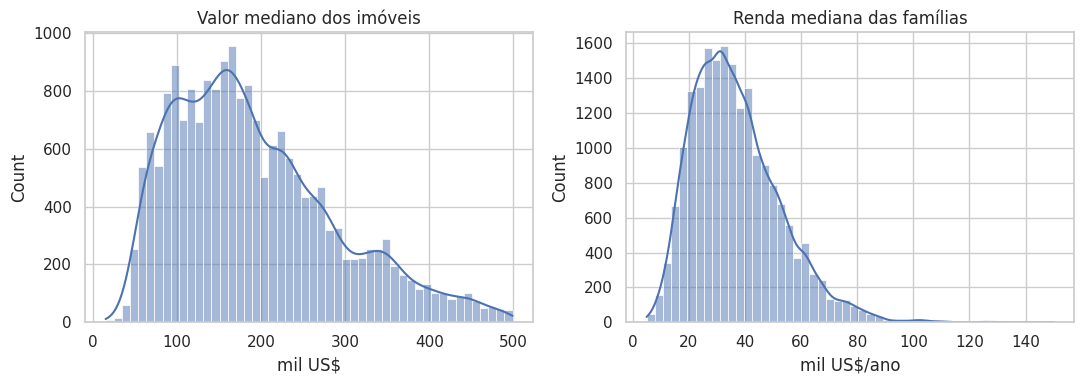

In [7]:
display(df.describe().T)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["valor_mil"], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Valor mediano dos imóveis"); ax[0].set_xlabel("mil US$")
sns.histplot(df["renda_mil"], bins=50, kde=True, ax=ax[1]); ax[1].set_title("Renda mediana das famílias"); ax[1].set_xlabel("mil US$/ano")
plt.tight_layout(); plt.savefig("fig_00_distribuicao.png", dpi=150); plt.show()

---
# Etapa 02 — Distribuição Normal de Probabilidade (1,0 ponto)

**Variável analisada:** `renda_mil` — renda mediana anual das famílias da comunidade (mil US$).

Considera-se a aproximação `X ~ N(μ, σ²)`, com média e desvio padrão populacional calculados a partir dos registros.

média = 36.7714 | mediana = 34.5000 | desvio padrão (pop.) = 15.6801

a) P(X < média)   = 0.5000 (50.00%) -> evento equiprovável (chance igual de ocorrer ou não)
b) P(X > mediana) = 0.5576 (55.76%) -> evento provável (p > 0,5)


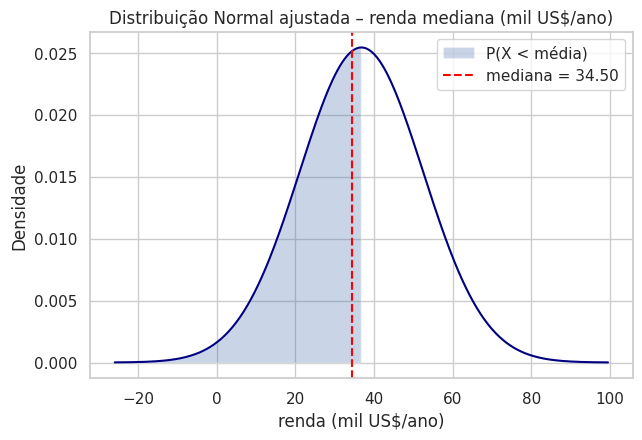

In [8]:
def classifica(p, tol=0.005):
    if p <= 0: return "evento impossível"
    if p >= 1: return "evento certo"
    if abs(p - 0.5) <= tol: return "evento equiprovável (chance igual de ocorrer ou não)"
    if p < 0.5: return "evento improvável (p < 0,5)"
    return "evento provável (p > 0,5)"

X = df["renda_mil"]
mu, sigma, mediana = X.mean(), X.std(ddof=0), X.median()
print(f"média = {mu:.4f} | mediana = {mediana:.4f} | desvio padrão (pop.) = {sigma:.4f}")

pa = stats.norm.cdf(mu, loc=mu, scale=sigma)                  # a) P(X < média)
print(f"\na) P(X < média)   = {pa:.4f} ({pa:.2%}) -> {classifica(pa)}")
pb = 1 - stats.norm.cdf(mediana, loc=mu, scale=sigma)         # b) P(X > mediana)
print(f"b) P(X > mediana) = {pb:.4f} ({pb:.2%}) -> {classifica(pb)}")

xs = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
plt.plot(xs, stats.norm.pdf(xs, mu, sigma), color="navy")
plt.fill_between(xs, stats.norm.pdf(xs, mu, sigma), where=xs < mu, alpha=.3, label="P(X < média)")
plt.axvline(mediana, color="red", ls="--", label=f"mediana = {mediana:.2f}")
plt.title("Distribuição Normal ajustada – renda mediana (mil US$/ano)"); plt.xlabel("renda (mil US$/ano)"); plt.ylabel("Densidade")
plt.legend(); plt.savefig("fig_01_normal.png", dpi=150, bbox_inches="tight"); plt.show()

### Interpretação dos resultados
Na normal, a média divide a curva em duas metades, logo P(X < média) = 50% (evento equiprovável). Já P(X > mediana) depende da distância entre mediana e média: como a renda real é assimétrica à direita, a mediana fica abaixo da média e a probabilidade calculada fica acima de 50%, classificando o evento como **provável**. Essa diferença mostra uma limitação da hipótese de normalidade para esta variável.

---
# Etapa 03 — Testes de hipóteses para a média (1,0 ponto)

**Variável analisada:** `renda_mil`. O desvio padrão de referência é o populacional da base (σ conhecido), portanto usa-se o **teste Z** unilateral, com amostras aleatórias reprodutíveis.

- **Teste A:** H₁: média amostral < média de referência; α = 6%; n = 20.
- **Teste B:** H₁: média amostral > média de referência; α = 9%; n = 25.

=== a) H1: média amostral MENOR que a populacional | α = 6% | n = 20 ===
H0: μ = 36.7714  |  H1: μ < μ₀  |  α = 6%  |  n = 20  |  σ = 15.6801
média amostral = 39.7722  | z calculado = 0.8559 | z crítico = -1.5548 | p-valor = 0.8040
Decisão: NÃO REJEITA H0 (sem evidência suficiente a favor de H1)

=== b) H1: média amostral MAIOR que a populacional | α = 9% | n = 25 ===
H0: μ = 36.7714  |  H1: μ > μ₀  |  α = 9%  |  n = 25  |  σ = 15.6801
média amostral = 36.7159  | z calculado = -0.0177 | z crítico = 1.3408 | p-valor = 0.5071
Decisão: NÃO REJEITA H0 (sem evidência suficiente a favor de H1)


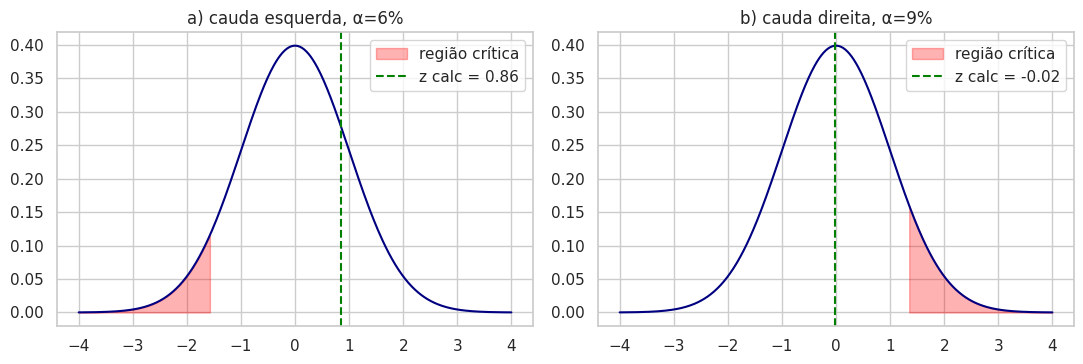

In [9]:
def teste_z(x_pop, n, alpha, cauda, seed):
    mu0, sig = x_pop.mean(), x_pop.std(ddof=0)
    amostra = x_pop.sample(n=n, random_state=seed)
    xbar = amostra.mean()
    z = (xbar - mu0) / (sig / np.sqrt(n))
    if cauda == "menor":
        zc = stats.norm.ppf(alpha); p = stats.norm.cdf(z); rejeita = z < zc; h1 = "μ < μ₀"
    else:
        zc = stats.norm.ppf(1 - alpha); p = 1 - stats.norm.cdf(z); rejeita = z > zc; h1 = "μ > μ₀"
    print(f"H0: μ = {mu0:.4f}  |  H1: {h1}  |  α = {alpha:.0%}  |  n = {n}  |  σ = {sig:.4f}")
    print(f"média amostral = {xbar:.4f}  | z calculado = {z:.4f} | z crítico = {zc:.4f} | p-valor = {p:.4f}")
    print("Decisão:", "REJEITA H0 (evidência a favor de H1)" if rejeita else "NÃO REJEITA H0 (sem evidência suficiente a favor de H1)")
    return xbar, z, zc, p, rejeita

print("=== a) H1: média amostral MENOR que a populacional | α = 6% | n = 20 ==="); ta = teste_z(df["renda_mil"], 20, 0.06, "menor", SEED)
print("\n=== b) H1: média amostral MAIOR que a populacional | α = 9% | n = 25 ==="); tb = teste_z(df["renda_mil"], 25, 0.09, "maior", SEED)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.linspace(-4, 4, 400)
for a, (res, cauda, t) in zip(ax, [(ta, "menor", "a) cauda esquerda, α=6%"), (tb, "maior", "b) cauda direita, α=9%")]):
    a.plot(x, stats.norm.pdf(x), color="navy"); zc = res[2]
    a.fill_between(x, stats.norm.pdf(x), where=(x < zc) if cauda == "menor" else (x > zc), color="red", alpha=.3, label="região crítica")
    a.axvline(res[1], color="green", ls="--", label=f"z calc = {res[1]:.2f}"); a.set_title(t); a.legend()
plt.tight_layout(); plt.savefig("fig_02_testes_z.png", dpi=150); plt.show()

### Interpretação dos testes
Compare o Z calculado com o crítico e o p-valor com α: se o p-valor for menor que α (ou Z cair na região crítica), rejeita-se H₀; caso contrário, não se rejeita. Não rejeitar H₀ não comprova igualdade das médias — apenas indica que a amostra não trouxe evidência suficiente a favor de H₁. Como as amostras são pequenas e aleatórias, o resultado pode variar com a semente.

---
# Etapa 04 — Análise bivariada e regressão linear simples (2,0 pontos)

**Pergunta:** comunidades com renda mais alta tendem a ter imóveis mais valorizados?

- **x:** `renda_mil` — renda mediana anual (mil US$).
- **y:** `valor_mil` — valor mediano dos imóveis (mil US$).

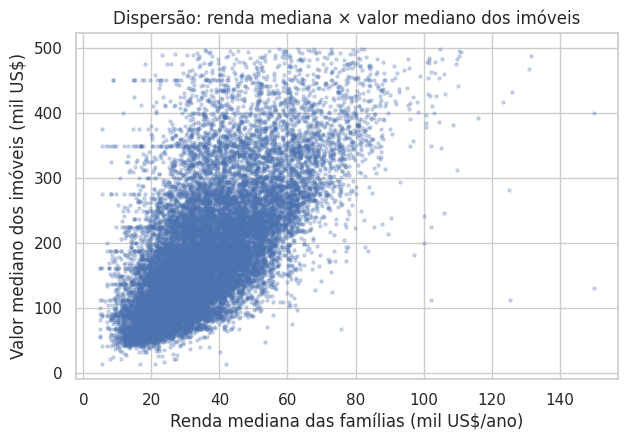

In [10]:
x = df["renda_mil"]; y = df["valor_mil"]
plt.scatter(x, y, s=5, alpha=.25)
plt.title("Dispersão: renda mediana × valor mediano dos imóveis")
plt.xlabel("Renda mediana das famílias (mil US$/ano)"); plt.ylabel("Valor mediano dos imóveis (mil US$)")
plt.savefig("fig_03_dispersao.png", dpi=150, bbox_inches="tight"); plt.show()

### a) Gráfico de dispersão
Observe a direção geral da associação, a dispersão ao redor da tendência e possíveis valores extremos.

In [11]:
cov = np.cov(x, y, ddof=1)[0, 1]
r, p_r = stats.pearsonr(x, y)
print(f"Covariância amostral = {cov:.4f}")
print(f"Correlação de Pearson r = {r:.4f} (p-valor = {p_r:.3e})")
forca = "muito fraca" if abs(r) < .2 else "fraca" if abs(r) < .4 else "moderada" if abs(r) < .7 else "forte"
print(f"-> correlação linear {forca} e {'positiva' if r > 0 else 'negativa'}")

Covariância amostral = 987.9382
Correlação de Pearson r = 0.6484 (p-valor = 0.000e+00)
-> correlação linear moderada e positiva


### b) Covariância e correlação de Pearson
A covariância indica o sentido da variação conjunta (depende das unidades); o coeficiente r (−1 a +1) resume intensidade e direção da relação linear. **Correlação não implica causalidade.**

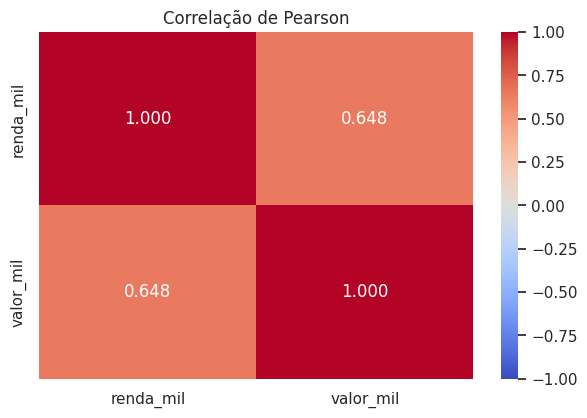

In [12]:
sns.heatmap(df[["renda_mil", "valor_mil"]].corr(), annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação de Pearson"); plt.savefig("fig_04_corr_bivariada.png", dpi=150, bbox_inches="tight"); plt.show()

Equação: valor_mil = 44.4756 + 4.0180 · renda_mil


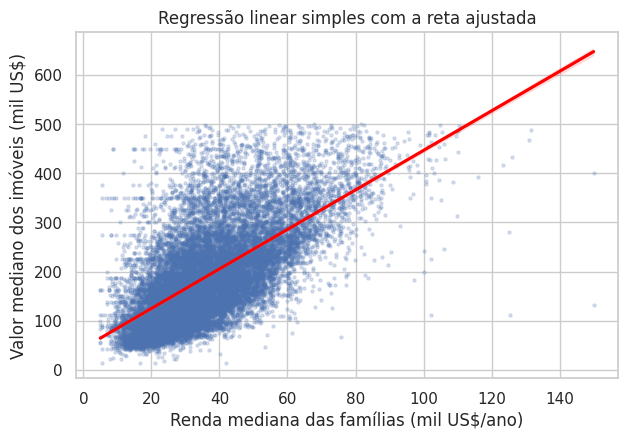

R² = 0.4205 (42.05% da variação de y explicada por x)
Teste F = 14180.43 | p-valor = 0.000e+00 -> modelo significativo (rejeita H0: β1=0)


In [13]:
res = stats.linregress(x, y)
b1, b0 = res.slope, res.intercept
print(f"Equação: valor_mil = {b0:.4f} + {b1:.4f} · renda_mil")
sns.regplot(x=x, y=y, scatter_kws={"s": 5, "alpha": .2}, line_kws={"color": "red"})
plt.title("Regressão linear simples com a reta ajustada")
plt.xlabel("Renda mediana das famílias (mil US$/ano)"); plt.ylabel("Valor mediano dos imóveis (mil US$)")
plt.savefig("fig_05_reta_regressao.png", dpi=150, bbox_inches="tight"); plt.show()

n = len(x); yhat = b0 + b1 * x
sst = ((y - y.mean())**2).sum(); sse = ((y - yhat)**2).sum(); ssr = sst - sse
r2 = ssr / sst
F = (ssr / 1) / (sse / (n - 2)); pF = stats.f.sf(F, 1, n - 2)
print(f"R² = {r2:.4f} ({r2:.2%} da variação de y explicada por x)")
print(f"Teste F = {F:.2f} | p-valor = {pF:.3e} -> {'modelo significativo (rejeita H0: β1=0)' if pF < .05 else 'modelo NÃO significativo'}")

### d–e) Equação, ajuste e teste F
O coeficiente angular é a variação esperada do valor mediano (mil US$) para cada +1 mil US$/ano de renda mediana. O R² mede a proporção da variação de y explicada pelo modelo; o teste F verifica se o modelo supera um modelo sem variável explicativa (H₀: β₁ = 0).

In [14]:
renda_nova = 50   # mil US$/ano
y_prev = b0 + b1 * renda_nova
s = np.sqrt(sse / (n - 2)); xm = x.mean(); sxx = ((x - xm)**2).sum()
se_pred = s * np.sqrt(1 + 1/n + (renda_nova - xm)**2 / sxx); tcrit = stats.t.ppf(.975, n - 2)
print(f"Previsão para renda mediana = {renda_nova} mil US$/ano: valor ≈ {y_prev:,.1f} mil US$")
print(f"Intervalo de previsão 95%: {y_prev - tcrit*se_pred:,.1f} a {y_prev + tcrit*se_pred:,.1f} mil US$")

Previsão para renda mediana = 50 mil US$/ano: valor ≈ 245.4 mil US$
Intervalo de previsão 95%: 100.4 a 390.4 mil US$


---
# Etapa 05 — Regressão linear múltipla (2,0 pontos)

- **y:** `valor_mil`.
- **Explicativas:** `renda_mil`, `idade_mediana` (anos), `comodos_dom` (cômodos por domicílio) e `pessoas_dom` (pessoas por domicílio).

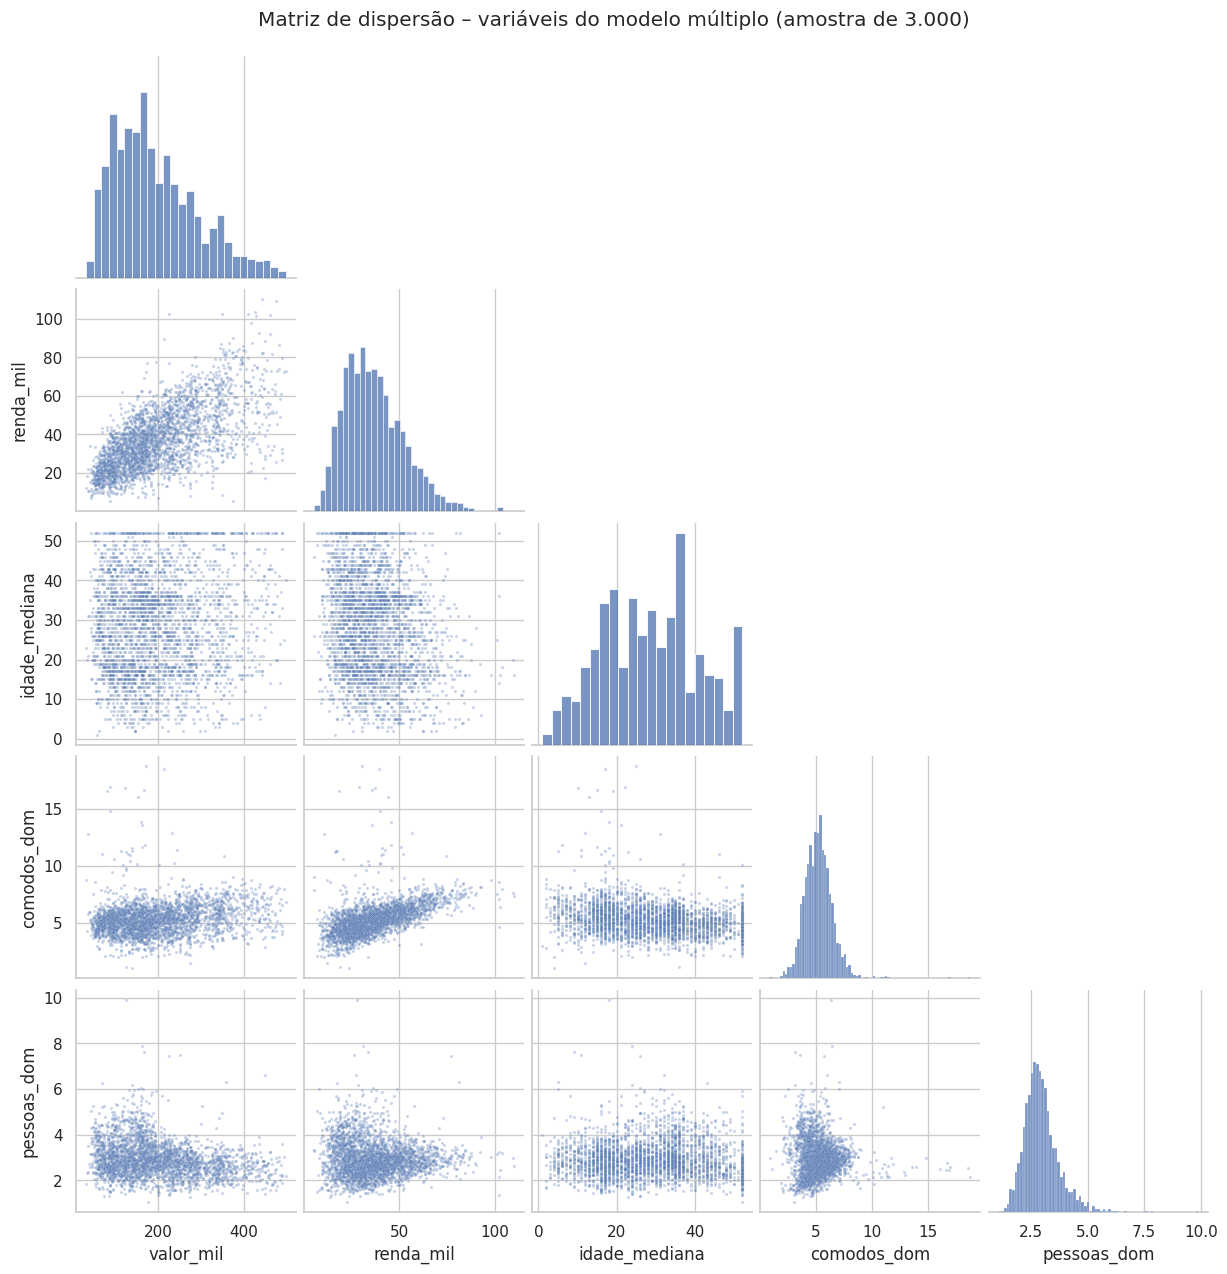

In [15]:
vars_m = ["valor_mil", "renda_mil", "idade_mediana", "comodos_dom", "pessoas_dom"]
M = df[vars_m]
g = sns.pairplot(M.sample(min(3000, len(M)), random_state=SEED), corner=True, plot_kws={"s": 5, "alpha": .3})
g.fig.suptitle("Matriz de dispersão – variáveis do modelo múltiplo (amostra de 3.000)", y=1.02)
g.savefig("fig_06_pairplot.png", dpi=130); plt.show()

### a) Matriz de dispersão
Observe a relação de cada variável explicativa com o valor dos imóveis e relações fortes entre as próprias explicativas (multicolinearidade).

Matriz de covariância:


,valor_mil,renda_mil,idade_mediana,comodos_dom,pessoas_dom
valor_mil,"9,441.0616",987.9382,78.5776,27.1734,-18.0762
renda_mil,987.9382,245.8780,-38.5373,11.8497,-0.6401
idade_mediana,78.5776,-38.5373,156.1248,-4.3213,0.1336
comodos_dom,27.1734,11.8497,-4.3213,1.8843,-0.0583
pessoas_dom,-18.0762,-0.6401,0.1336,-0.0583,0.5869


Matriz de correlação de Pearson:


,valor_mil,renda_mil,idade_mediana,comodos_dom,pessoas_dom
valor_mil,1.0000,0.6484,0.0647,0.2037,-0.2428
renda_mil,0.6484,1.0000,-0.1967,0.5505,-0.0533
idade_mediana,0.0647,-0.1967,1.0000,-0.2519,0.0140
comodos_dom,0.2037,0.5505,-0.2519,1.0000,-0.0554
pessoas_dom,-0.2428,-0.0533,0.0140,-0.0554,1.0000


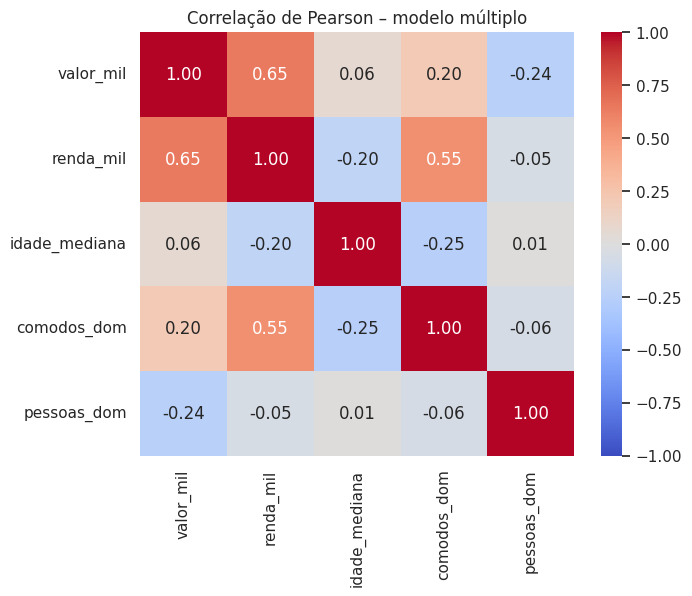

In [16]:
print("Matriz de covariância:"); display(M.cov())
print("Matriz de correlação de Pearson:"); display(M.corr())
plt.figure(figsize=(7, 5.5))
sns.heatmap(M.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação de Pearson – modelo múltiplo"); plt.savefig("fig_07_corr_multipla.png", dpi=150, bbox_inches="tight"); plt.show()

### b–c) Matrizes de covariância e correlação
A covariância depende das unidades; a correlação padroniza entre −1 e +1. Observe as correlações com `valor_mil` e entre as variáveis explicativas.

In [17]:
exp_ = ["renda_mil", "idade_mediana", "comodos_dom", "pessoas_dom"]
Xm = np.column_stack([np.ones(len(M)), M[exp_].values]); ym = M["valor_mil"].values
beta, *_ = np.linalg.lstsq(Xm, ym, rcond=None)
n, k = Xm.shape; yhat = Xm @ beta
sse = ((ym - yhat)**2).sum(); sst = ((ym - ym.mean())**2).sum(); ssr = sst - sse
sigma2 = sse / (n - k); cov_b = sigma2 * np.linalg.inv(Xm.T @ Xm)
se = np.sqrt(np.diag(cov_b)); tvals = beta / se; pvals = 2 * stats.t.sf(np.abs(tvals), n - k)
tab = pd.DataFrame({"coef": beta, "erro_padrão": se, "t": tvals, "p-valor": pvals}, index=["const"] + exp_)
display(tab)
eq = f"valor_mil = {beta[0]:.4f}" + "".join(f" {b:+.4f}·{v}" for b, v in zip(beta[1:], exp_))
print("Equação:", eq)

r2 = ssr / sst; r2aj = 1 - (1 - r2) * (n - 1) / (n - k)
F = (ssr / (k - 1)) / (sse / (n - k)); pF = stats.f.sf(F, k - 1, n - k)
print(f"\nR² = {r2:.4f} | R² ajustado = {r2aj:.4f}")
print(f"Teste F = {F:.2f} (gl = {k-1}, {n-k}) | p-valor = {pF:.3e} -> {'modelo globalmente significativo' if pF < .05 else 'modelo NÃO significativo'}")

vif = {}
for v in exp_:
    others = np.column_stack([np.ones(len(M))] + [M[o].values for o in exp_ if o != v])
    b, *_ = np.linalg.lstsq(others, M[v].values, rcond=None)
    rj = 1 - ((M[v].values - others @ b)**2).sum() / ((M[v].values - M[v].mean())**2).sum()
    vif[v] = 1 / (1 - rj)
print("VIF:", {k_: round(float(v_), 2) for k_, v_ in vif.items()}, "(valores < 5 sugerem multicolinearidade moderada/baixa)")

,coef,erro_padrão,t,p-valor
const,129.0718,3.1625,40.8137,0.0000
renda_mil,4.8133,0.0366,131.5197,0.0000
idade_mediana,1.3376,0.0396,33.7741,0.0000
comodos_dom,-13.6228,0.4236,-32.1588,0.0000
pessoas_dom,-27.2077,0.6247,-43.5525,0.0000


Equação: valor_mil = 129.0718 +4.8133·renda_mil +1.3376·idade_mediana -13.6228·comodos_dom -27.2077·pessoas_dom

R² = 0.5277 | R² ajustado = 0.5276
Teste F = 5458.80 (gl = 4, 19543) | p-valor = 0.000e+00 -> modelo globalmente significativo
VIF: {'renda_mil': 1.44, 'idade_mediana': 1.07, 'comodos_dom': 1.48, 'pessoas_dom': 1.0} (valores < 5 sugerem multicolinearidade moderada/baixa)


### d–e) Equação e avaliação do modelo
Cada coeficiente é a associação estimada com o valor dos imóveis mantendo as demais variáveis constantes. Compare R² ajustado com o do modelo simples, avalie o teste F e o VIF, e analise os resíduos no gráfico seguinte.

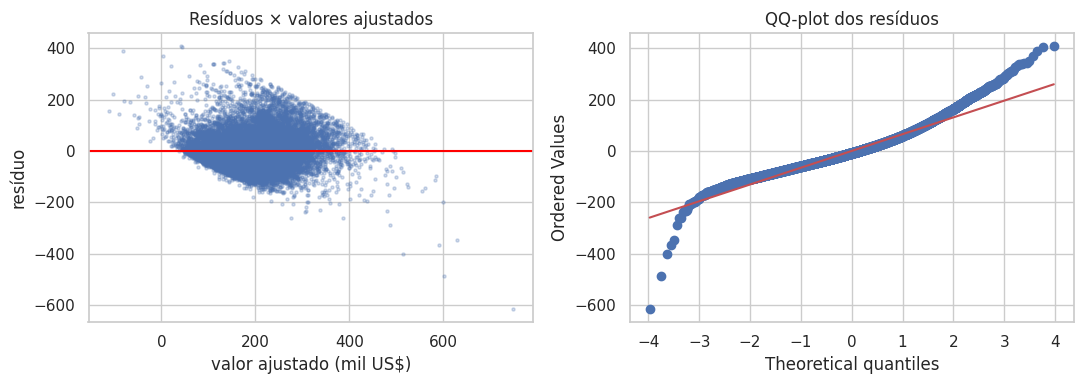

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
res_ = ym - yhat
ax[0].scatter(yhat, res_, s=5, alpha=.25); ax[0].axhline(0, color="red"); ax[0].set_title("Resíduos × valores ajustados"); ax[0].set_xlabel("valor ajustado (mil US$)"); ax[0].set_ylabel("resíduo")
stats.probplot(res_, dist="norm", plot=ax[1]); ax[1].set_title("QQ-plot dos resíduos")
plt.tight_layout(); plt.savefig("fig_08_residuos.png", dpi=150); plt.show()

In [19]:
novo = {"renda_mil": 40.0, "idade_mediana": 30.0, "comodos_dom": 5.0, "pessoas_dom": 3.0}
xn = np.array([1] + [novo[v] for v in exp_])
yp = xn @ beta
print("Cenário:", novo)
print(f"Previsão do valor mediano dos imóveis ≈ {yp:,.1f} mil US$")

Cenário: {'renda_mil': 40.0, 'idade_mediana': 30.0, 'comodos_dom': 5.0, 'pessoas_dom': 3.0}
Previsão do valor mediano dos imóveis ≈ 212.0 mil US$


---
# Etapa 06 — Regressão logística binária (2,0 pontos)

**Variável resposta:** `alto_valor` = 1 se o valor mediano dos imóveis da comunidade está **acima da mediana** da base; 0 caso contrário.

**Explicativas quantitativas:** `renda_mil`, `idade_mediana`, `comodos_dom` e `pessoas_dom`. Divisão treino/teste 70/30 estratificada; a avaliação principal usa o conjunto de teste.

In [20]:
df["alto_valor"] = (df["valor_mil"] > df["valor_mil"].median()).astype(int)
print(df["alto_valor"].value_counts(normalize=True).rename("proporção"))
exp_l = ["renda_mil", "idade_mediana", "comodos_dom", "pessoas_dom"]
Xl, yl = df[exp_l], df["alto_valor"]
Xtr, Xte, ytr, yte = train_test_split(Xl, yl, test_size=.3, stratify=yl, random_state=SEED)

lr = LogisticRegression(penalty=None, max_iter=10000).fit(Xtr, ytr)
b0, bs = lr.intercept_[0], lr.coef_[0]
termos = " ".join(f"{b:+.4f}·{v}" for b, v in zip(bs, exp_l))
print(f"\nlogit(p) = ln(p/(1-p)) = {b0:.4f} {termos}")
print("p = 1 / (1 + e^-logit)")
print("\nRazões de chances (odds ratio = e^β):")
display(pd.Series(np.exp(bs), index=exp_l, name="odds ratio"))

alto_valor
0   0.5006
1   0.4994
Name: proporção, dtype: float64

logit(p) = ln(p/(1-p)) = -0.6183 +0.1575·renda_mil +0.0340·idade_mediana -0.6552·comodos_dom -0.8892·pessoas_dom
p = 1 / (1 + e^-logit)

Razões de chances (odds ratio = e^β):


,odds ratio
renda_mil,1.1706
idade_mediana,1.0346
comodos_dom,0.5194
pessoas_dom,0.4110


--- TREINO --- acurácia = 0.8011
        previsto 0  previsto 1
real 0        5523        1327
real 1        1395        5438
sensibilidade (recall) = 0.7958 | especificidade = 0.8063 | precisão = 0.8038

--- TESTE --- acurácia = 0.7923
        previsto 0  previsto 1
real 0        2349         587
real 1         631        2298
sensibilidade (recall) = 0.7846 | especificidade = 0.8001 | precisão = 0.7965



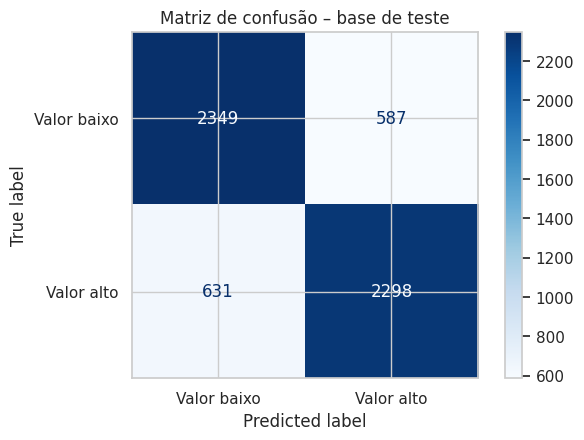

Referência: classificar tudo como a classe majoritária daria acurácia de ≈ 0.5006


In [21]:
for nome, Xs, ys in [("TREINO", Xtr, ytr), ("TESTE", Xte, yte)]:
    pred = lr.predict(Xs); cm = confusion_matrix(ys, pred)
    print(f"--- {nome} --- acurácia = {accuracy_score(ys, pred):.4f}")
    print(pd.DataFrame(cm, index=["real 0", "real 1"], columns=["previsto 0", "previsto 1"]))
    tn, fp, fn, tp = cm.ravel()
    print(f"sensibilidade (recall) = {tp/(tp+fn):.4f} | especificidade = {tn/(tn+fp):.4f} | precisão = {tp/(tp+fp):.4f}\n")
ConfusionMatrixDisplay(confusion_matrix(yte, lr.predict(Xte)), display_labels=["Valor baixo", "Valor alto"]).plot(cmap="Blues")
plt.title("Matriz de confusão – base de teste"); plt.savefig("fig_09_matriz_confusao.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Referência: classificar tudo como a classe majoritária daria acurácia de ≈ {max(yte.mean(), 1-yte.mean()):.4f}")

### b) Matriz de confusão e acurácia
A matriz compara classes reais e previstas; a acurácia é a proporção de acertos. Compare com a linha de base (~50%), avalie sensibilidade, especificidade e precisão e verifique se a diferença entre treino e teste sugere sobreajuste.

In [22]:
novo = pd.DataFrame([{"renda_mil": 60.0, "idade_mediana": 25.0, "comodos_dom": 6.0, "pessoas_dom": 2.5}])
prob = lr.predict_proba(novo)[0, 1]; classe = int(prob >= .5)
print("Cenário: renda 60 mil US$/ano, idade mediana 25 anos, 6 cômodos e 2,5 pessoas por domicílio")
print(f"P(valor acima da mediana) = {prob:.4f} -> classe prevista = {classe} ({'ALTO' if classe else 'BAIXO'})")

Cenário: renda 60 mil US$/ano, idade mediana 25 anos, 6 cômodos e 2,5 pessoas por domicílio
P(valor acima da mediana) = 0.9714 -> classe prevista = 1 (ALTO)


---
# Etapa 07 — Conclusões, limitações e aplicação no CitizenTech


# Conclusão do Estudo — Moradia e Desigualdade Urbana

Com base nas análises probabilísticas, testes de hipóteses e modelagens estatísticas realizadas sobre os dados do Censo de 1990 da Califórnia, apresentamos as seguintes conclusões consolidadas:

### 1. Principais Resultados e Modelos
- **Variável de Maior Impacto:** A **renda mediana das famílias (`renda_mil`)** demonstrou ser o fator individual mais fortemente associado ao valor mediano dos imóveis (`valor_mil`), apresentando uma correlação linear moderada e positiva ($r = 0.6484$, com significância estatística de $p < 0.001$).
- **Regressão Linear Múltipla:** Ao integrarmos a idade das construções, o número de cômodos e o número de pessoas por domicílio, obtivemos um **$R^2$ Ajustado de 0.5276**. Isso significa que **52,76% da variação** nos valores dos imóveis é explicada conjuntamente por essas quatro características socioespaciais. O teste F global foi altamente significativo ($p < 0.001$), e todos os coeficientes individuais apresentaram relevância estatística, mantendo-se livres de problemas graves de multicolinearidade (VIF < 1.5).
- **Regressão Logística Binária:** O modelo classificador treinado para prever se uma comunidade possui valor imobiliário acima da mediana da base alcançou uma **acurácia de 79,23% no conjunto de teste** (um ganho substancial sobre a linha de base de ~50%). A sensibilidade (recall) foi de 78,46% e a especificidade de 80,01%, indicando um comportamento equilibrado e robusto sem indícios de sobreajuste (overfitting).

### 2. Aplicação no Planejamento Urbano (CitizenTech)
Estes modelos analíticos oferecem ferramentas quantitativas poderosas para a gestão pública e movimentos sociais (CitizenTech):
- **Detecção de Desalinhamentos:** Permite identificar comunidades onde o valor imobiliário estimado destoa significativamente do padrão preditivo local, sinalizando potenciais processos de especulação imobiliária extrema ou de subvalorização severa.
- **Políticas de Acessibilidade:** Auxilia no diagnóstico prévio para implantação de habitações de interesse social e infraestrutura urbana, correlacionando a densidade ocupacional e a renda local com a barreira econômica de acesso à moradia.

### 3. Limitações Críticas da Investigação
- **Anacronismo e Escopo Geográfico:** Os dados refletem a realidade da Califórnia em 1990. Não representam a dinâmica imobiliária do Brasil nem do período atual, exigindo cautela na generalização direta.
- **Falácia Ecológica:** Como a unidade de análise é o setor censitário/comunidade (bloco), as relações identificadas descrevem o comportamento agregado do território, não podendo ser aplicadas de forma absoluta a indivíduos ou imóveis isolados dentro dessas comunidades.
- **Remoção de Censura:** Excluir os registros censurados no teto de US$ 500 mil atenuou distorções estatísticas nas regressões, mas limitou a capacidade do modelo de representar adequadamente as áreas de altíssimo padrão.
- **Correlação vs. Causalidade:** Os coeficientes estimados apontam padrões consistentes de associação matemática, porém não estabelecem uma relação direta de causa e efeito.
